# 01 — Data download and exploratory analysis

**Goal:** understand what the Atlas of Living Australia (ALA) records of *Rhinella marina* can and cannot tell us about the invasion front, before any modelling.

Key questions:
1. Are the records biologically plausible (dates, locations)?
2. How much of the temporal signal is sampling effort rather than toads?
3. Which records do we keep, and why?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from download import download_australia_outline, download_occurrences

FIGURES = PROJECT_ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

raw = pd.read_csv(download_occurrences(), low_memory=False)
raw.shape

Using cached file: rhinella_marina_ala.csv


(73293, 13)

## 1. Missing values

In [2]:
raw.isna().mean().sort_values(ascending=False).round(3)

multimedia                       0.884
coordinateUncertaintyInMeters    0.518
month                            0.214
eventDate                        0.165
year                             0.060
decimalLatitude                  0.010
decimalLongitude                 0.010
stateProvince                    0.010
recordID                         0.000
scientificName                   0.000
basisOfRecord                    0.000
occurrenceStatus                 0.000
dataResourceName                 0.000
dtype: float64

Half of the records have no coordinate uncertainty, and ~6% have no year. Records without a year are useless for a spatiotemporal model; missing uncertainty is not a reason to discard (we would lose half the data).

## 2. Plausibility: where and when

In [3]:
raw["stateProvince"].value_counts(dropna=False)

stateProvince
Queensland                   27883
Northern Territory           22646
Western Australia            15850
New South Wales               6078
NaN                            713
Morobe Province                 65
Central                         22
Victoria                        10
National Capital District       10
South Australia                  4
New Britain                      4
Manus Province                   4
East New Britain Province        3
Choiseul Province                1
Name: count, dtype: int64

Some records come from Papua New Guinea and the Solomon Islands (part of the native/introduced Pacific range, outside our scope). The few Victoria and South Australia records are mostly museum specimens or isolated sightings: toads hitchhiking in freight, not an established front.

In [4]:
raw.groupby("stateProvince")["year"].agg(["min", "count"]).sort_values("min")

,min,count
stateProvince,,
Queensland,1935.0,25193
New Britain,1962.0,4
New South Wales,1962.0,4476
East New Britain Province,1966.0,1
Central,1967.0,22
Morobe Province,1972.0,1
Northern Territory,1974.0,22620
Victoria,1990.0,10
South Australia,1998.0,3


Sanity check against the known invasion history:

| State | First record (ALA) | Known history |
|---|---|---|
| Queensland | 1935 | Introduced near Gordonvale in 1935 ✔ |
| New South Wales | 1962 | Reached northern NSW in the 1960s ✔ |
| Northern Territory | 1974 | Front reached the NT in the early 1980s — **check** |
| Western Australia | 2010 | Front crossed into WA around 2009 ✔ |

The data broadly reproduce the history, which gives some confidence. Let's look at the suspicious early NT records.

In [5]:
raw.loc[raw["stateProvince"] == "Northern Territory"].nsmallest(5, "year")[
    ["year", "decimalLatitude", "decimalLongitude", "basisOfRecord", "dataResourceName"]
]

,year,decimalLatitude,decimalLongitude,basisOfRecord,dataResourceName
54172,1974.0,-12.450000,130.833000,PRESERVED_SPECIMEN,Northern Territory Museum and Art Gallery prov...
5894,1983.0,-13.850000,136.417000,PRESERVED_SPECIMEN,Northern Territory Museum and Art Gallery prov...
60774,1983.0,-17.217000,137.950000,PRESERVED_SPECIMEN,Northern Territory Museum and Art Gallery prov...
70436,1983.0,-17.217000,137.950000,PRESERVED_SPECIMEN,Northern Territory Museum and Art Gallery prov...
16568,1984.0,-17.015212,137.967841,HUMAN_OBSERVATION,Fauna Atlas N.T.


The 1974 record is a museum specimen from **Darwin** (−12.45, 130.83), roughly 30 years before the front reached the city (mid-2000s). Most likely a toad transported by people. These *jump* records are real observations, but they do not represent the front: **any front-speed method we use in notebook 02 must be robust to them.** The 1983 records near the Gulf of Carpentaria are consistent with the front entering the NT from Queensland.

## 3. Sampling effort: who records toads, and when

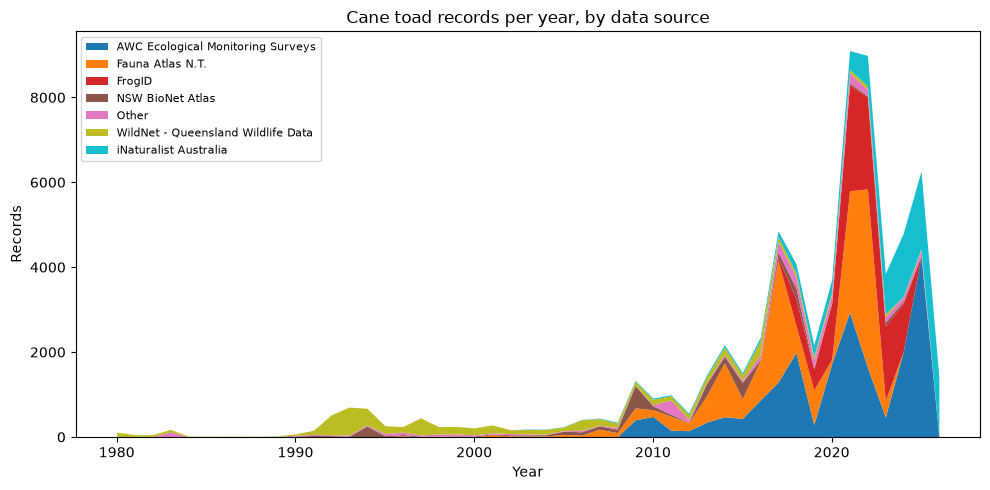

In [6]:
top_sources = raw["dataResourceName"].value_counts().head(6).index
by_source = (
    raw.assign(source=raw["dataResourceName"].where(raw["dataResourceName"].isin(top_sources), "Other"))
    .query("year >= 1980")
    .pivot_table(index="year", columns="source", values="recordID", aggfunc="count", fill_value=0)
)

ax = by_source.plot.area(figsize=(10, 5), linewidth=0, colormap="tab10")
ax.set(xlabel="Year", ylabel="Records", title="Cane toad records per year, by data source")
ax.legend(title=None, fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES / "01_records_by_source.png", dpi=150)

**The number of records per year is driven by who is surveying, not by how many toads there are.** Structured surveys (AWC Ecological Monitoring, NT Fauna Atlas) and citizen-science apps (FrogID from 2017, iNaturalist) dominate recent years. Any model that reads "more records" as "more toads" or "faster spread" will be wrong.

This is also why we do **not** filter to records with photos: only ~12% have media, and that filter would remove the structured surveys, which are the most reliable records we have.

In [7]:
raw["multimedia"].notna().groupby(raw["dataResourceName"]).mean().sort_values().tail(8).round(2)

dataResourceName
iNaturalist Australia                                        0.96
NatureMapr                                                   1.00
Camera trap surveys in Queensland's Wet Tropics 2022-2023    1.00
Earth Guardians Weekly Feed                                  1.00
Auswildlife                                                  1.00
B4C Road Kill Map                                            1.00
Encyclopedia of Life Images - Flickr Group                   1.00
feral.org.au                                                 1.00
Name: multimedia, dtype: float64

## 4. Duplicates

In [8]:
keys = ["decimalLatitude", "decimalLongitude", "eventDate"]
dup = raw.duplicated(keys, keep=False)
print(f"{dup.mean():.0%} of records share location and date with another record")
raw.loc[dup, "dataResourceName"].value_counts().head()

52% of records share location and date with another record


dataResourceName
AWC Ecological Monitoring Surveys     17411
Fauna Atlas N.T.                      13342
WildNet - Queensland Wildlife Data     1939
FrogID                                 1258
Northern Gulf Fauna Survey             1080
Name: count, dtype: int64

These are not errors: survey datasets record one row per individual. For the question *"was the toad present here at this time?"* they carry no extra information, so later we will collapse records to presence per grid cell and year.

## 5. Coordinate precision

In [9]:
raw["coordinateUncertaintyInMeters"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0)

count      35349.0
mean        1958.0
std        22930.0
min            1.0
50%           50.0
90%         3600.0
95%        10000.0
99%        29845.0
max      2753412.0
Name: coordinateUncertaintyInMeters, dtype: float64

We will model at a resolution of several kilometres, so records with uncertainty above 10 km are dropped. Records with unknown uncertainty are kept.

## 6. Cleaning

In [10]:
AUSTRALIAN_STATES = [
    "Queensland", "Northern Territory", "Western Australia", "New South Wales",
]
MAX_UNCERTAINTY_M = 10_000
INTRODUCTION_YEAR = 1935

steps = {"raw": len(raw)}
clean = raw.dropna(subset=["decimalLatitude", "decimalLongitude", "year"])
steps["has coordinates and year"] = len(clean)
clean = clean[clean["stateProvince"].isin(AUSTRALIAN_STATES)]
steps["mainland states with established populations"] = len(clean)
clean = clean[clean["year"] >= INTRODUCTION_YEAR]
steps["after introduction (1935)"] = len(clean)
clean = clean[~(clean["coordinateUncertaintyInMeters"] > MAX_UNCERTAINTY_M)]
steps["uncertainty <= 10 km or unknown"] = len(clean)
clean = clean.drop_duplicates(keys)
steps["unique location-date"] = len(clean)

pd.Series(steps, name="records").to_frame()

,records
raw,73293
has coordinates and year,68219
mainland states with established populations,68071
after introduction (1935),68071
uncertainty <= 10 km or unknown,67249
unique location-date,37719


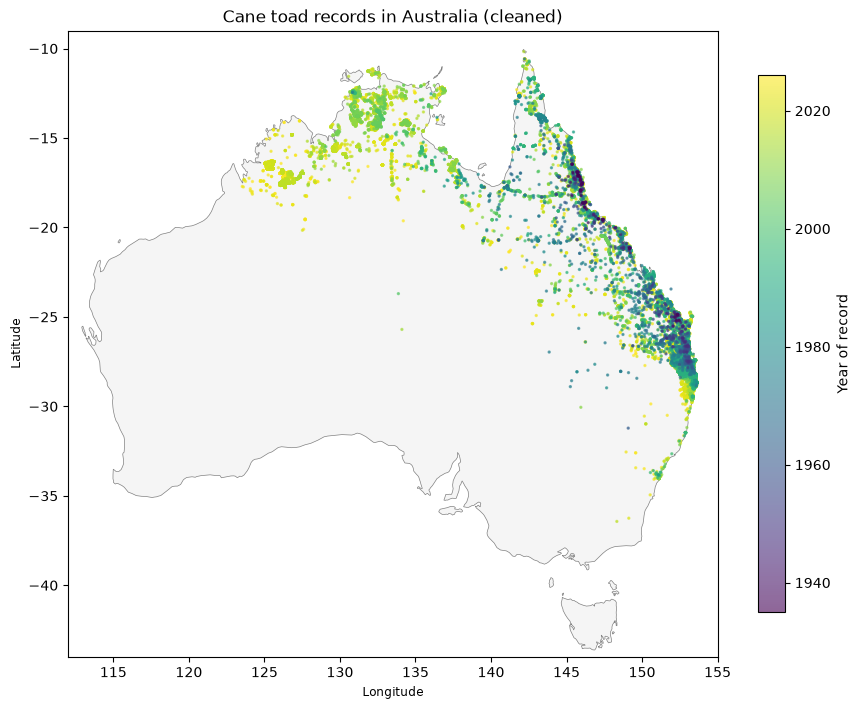

In [11]:
australia = download_australia_outline()
oldest_on_top = clean.sort_values("year", ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
australia.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
sc = ax.scatter(
    oldest_on_top["decimalLongitude"], oldest_on_top["decimalLatitude"],
    c=oldest_on_top["year"], cmap="viridis", s=2, alpha=0.6,
)
plt.colorbar(sc, ax=ax, label="Year of record", shrink=0.7)
ax.set(xlabel="Longitude", ylabel="Latitude", title="Cane toad records in Australia (cleaned)")
ax.set(xlim=(112, 155), ylim=(-44, -9))
plt.tight_layout()
plt.savefig(FIGURES / "01_records_map.png", dpi=150)

The colour gradient already shows the invasion: old records in eastern Queensland, recent ones in the Kimberley (WA) and northern NSW.

In [12]:
out = PROJECT_ROOT / "data" / "processed" / "rhinella_marina_clean.csv"
out.parent.mkdir(exist_ok=True)
clean.to_csv(out, index=False)
print(f"Saved {len(clean):,} records to {out.name}")

Saved 37,719 records to rhinella_marina_clean.csv


## Takeaways
- The data reproduce the known invasion history (QLD 1935 → NSW 1960s → NT → WA 2010).
- Record counts reflect survey effort; models must not interpret them as abundance.
- Media-based filtering would discard the most reliable (structured survey) data.
- Next notebook: estimate the invasion front position per year and its speed, by region.